# 04 - DATA VISUALISATION REVIEW EXERCISE - FLIGHTS (SOLUTION)

 Use the following datasets: "flights.csv" dataset contains information about the flights of an airport. "airlines.csv" dataset provides valuable information about flight routes, schedules, passenger demographics, and preferences, which airlines can leverage to optimize their operations and enhance customer experiences.


* You should read both datasets and import the relevant libraries first

In [1]:
import sys; sys.path.append('..')  # so data_utils.py in the repo root can be found
from data_utils import get_data  # downloads big files from GitHub Releases if missing

import matplotlib.pyplot as plt
import pandas as pd
import matplotlib
%matplotlib inline

# Read in data
flight_file = pd.read_csv(get_data('data/flights.csv'))
airline_file = pd.read_csv('data/airlines.csv')

A) You should check the shape of the datasets

B) You should find the number of NaN values in both datasets

C) You should remove the NaN values

D) After removing them, You should double-check the number of NaN values in both datasets. What do you notice in this case?

In [2]:
# A
flight_file.shape

(336776, 21)

In [3]:
# A
airline_file.shape

(98619, 15)

In [2]:
# B
flight_file.isna().sum()

id                   0
year                 0
month                0
day                  0
dep_time          8255
sched_dep_time       0
dep_delay         8255
arr_time          8713
sched_arr_time       0
arr_delay         9430
carrier              0
flight               0
tailnum           2512
origin               0
dest                 0
air_time          9430
distance             0
hour                 0
minute               0
time_hour            0
name                 0
dtype: int64

In [3]:
# B
airline_file.isna().sum()

Passenger ID            0
First Name              0
Last Name               0
Gender                  0
Age                     0
Nationality             0
Airport Name            0
Airport Country Code    0
Country Name            0
Airport Continent       0
Continents              0
Departure Date          0
Arrival Airport         0
Pilot Name              0
Flight Status           0
dtype: int64

In [4]:
# C
flight_file.dropna(inplace=True)
airline_file.dropna(inplace=True)

In [5]:
# D
airline_file.isna().sum()

Passenger ID            0
First Name              0
Last Name               0
Gender                  0
Age                     0
Nationality             0
Airport Name            0
Airport Country Code    0
Country Name            0
Airport Continent       0
Continents              0
Departure Date          0
Arrival Airport         0
Pilot Name              0
Flight Status           0
dtype: int64

In [8]:
# D
flight_file.isna().sum()

id                0
year              0
month             0
day               0
dep_time          0
sched_dep_time    0
dep_delay         0
arr_time          0
sched_arr_time    0
arr_delay         0
carrier           0
flight            0
tailnum           0
origin            0
dest              0
air_time          0
distance          0
hour              0
minute            0
time_hour         0
name              0
dtype: int64

E) Now, you should combine the flights DataFrame with the airlines DataFrame to include additional information about the carriers by matching the carrier column from flights with the Passenger ID column from airlines? Only keep the 'arr_delay' and 'name' column in the combined DataFrame.

Hint: use a left merge between flights and airlines

In [9]:
flight_file = flight_file.merge(airline_file, how='left', left_on='carrier', right_on='Passenger ID')
flights = flight_file[['arr_delay', 'name']]

F) You should filter flight delays between -60 and 120 minutes

In [10]:
flights = flights[flights['arr_delay'].between(-60, 120)]
flights.head(5)

,arr_delay,name
0,11.0,United Air Lines Inc.
1,20.0,United Air Lines Inc.
2,33.0,American Airlines Inc.
3,-18.0,JetBlue Airways
4,-25.0,Delta Air Lines Inc.


G) You should plot a histogram on a figure with size (9,7) using matplotlib with 40 bins (must always be an integer). The bars should be blue and their edges black.

H) Make sure that you add a title and labels to the figure

I) Show 2 other different binwidths and alpha values. Also, set 'density=True', what does this do?

Text(0, 0.5, 'Flights')

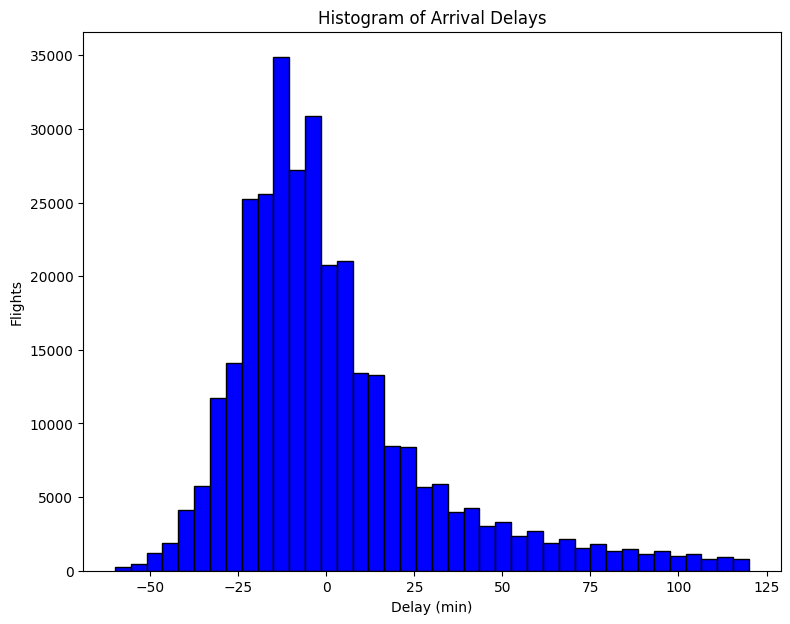

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

# Set the figure size
plt.figure(figsize=(9, 7))
# Make the histogram using matplotlib, bins must be integer
plt.hist(flights['arr_delay'], color='blue', edgecolor='black', bins=40)
# Add labels
plt.title('Histogram of Arrival Delays')
plt.xlabel('Delay (min)')
plt.ylabel('Flights')


Text(0, 0.5, 'Flights')

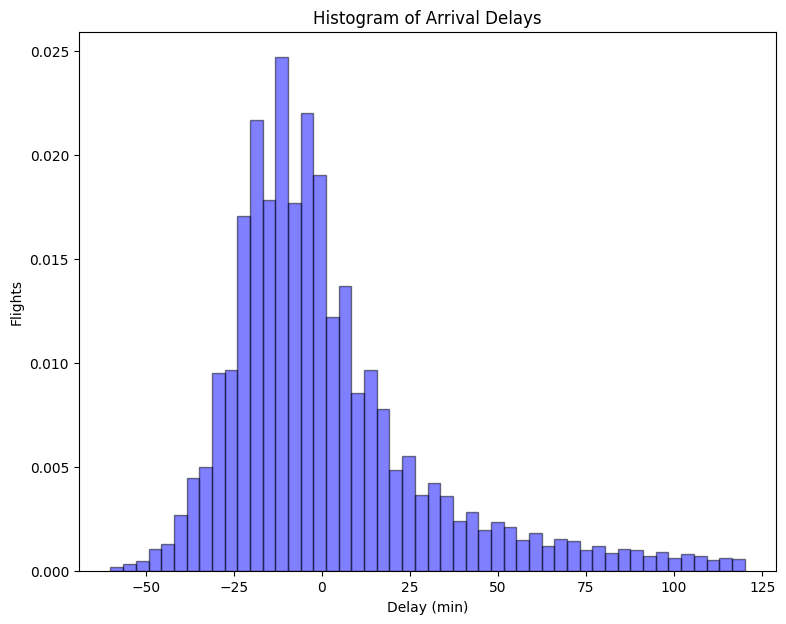

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

# Set the figure size
plt.figure(figsize=(9, 7))

# Make the histogram using matplotlib, bins must be integer
plt.hist(flights['arr_delay'], color='blue', edgecolor='black', bins=50, density=True, alpha=0.5)
# The alpha parameter controls the transparency of the histogram bars, while density=True normalizes the histogram so that the area under the bars sums to 1, showing probability density instead of raw counts.

# Add labels
plt.title('Histogram of Arrival Delays')
plt.xlabel('Delay (min)')
plt.ylabel('Flights')


How do the arrival delays compare between two different carriers (AA and DL) for flights with delays less than or equal to 250 minutes? To figure this out, we want to plot two histograms, one for each carrier's delays.

J) First, you should select delays from the two carriers into separate variables

K) Then, filter these delays to only include those between 0 and 250 minutes

L) Create a figure with size (12, 12)

M) You should define the histogram properties using a dictionary:
    density (True), bins (50), alpha (0.3), histtype ('stepfilled'), edge color (black)

What do these properties mean?

N) Plot two histograms, one for each carrier, on the same figure, give each an appropriate label

O) Set title, xlabel, ylabel and show the legend


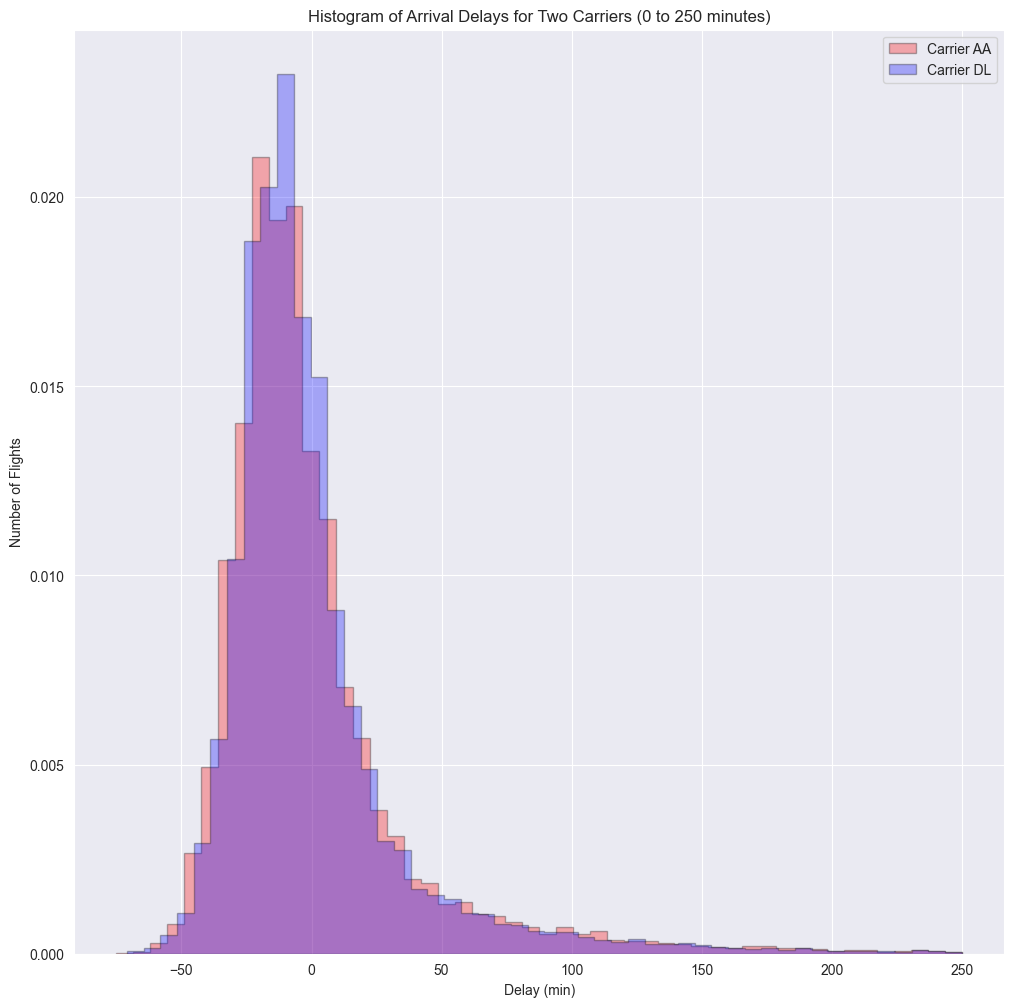

In [2]:
import matplotlib.pyplot as plt

# Selecting delays from two different carriers
carrier1_delays = flight_file[flight_file['carrier'] == 'AA']['arr_delay']
carrier2_delays = flight_file[flight_file['carrier'] == 'DL']['arr_delay']

# Filter delays to only include those less than or equal to 250 minutes
carrier1_delays = carrier1_delays[(carrier1_delays <= 250)]
carrier2_delays = carrier2_delays[(carrier2_delays <= 250)]

# Set the figure size
plt.figure(figsize=(12, 12))

# Define histogram properties
kwargs = {
    'bins': 50,  # Number of bins
    'alpha': 0.3,  # Transparency of the bars
    'density': True,
    'histtype': 'stepfilled', # This makes it a bit easier to read, only top of bars are drawn
    'edgecolor': 'black'  # Color of the edges
}

# Plot the histograms
plt.hist(carrier1_delays, **kwargs, label='Carrier AA', color='red')
plt.hist(carrier2_delays, **kwargs, label='Carrier DL', color='blue')

# Add titles and labels
plt.title('Histogram of Arrival Delays for Two Carriers (0 to 250 minutes)')
plt.xlabel('Delay (min)')
plt.ylabel('Number of Flights')
plt.legend()
